# Caso Práctico 2

## Implementación de CNNs

In [2]:
import keras
from keras.datasets import cifar100
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten
from keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Cargar el conjunto de datos CIFAR-100
(x_train, y_train), (x_test, y_test) = cifar100.load_data()
n_classes = 100

# Normalizar los datos de píxeles en el rango [0, 1]
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# Convertir las etiquetas a vectores one-hot
y_train = to_categorical(y_train, n_classes)
y_test = to_categorical(y_test, n_classes)

# Configurar la aumentación de datos
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    vertical_flip=False,
)

datagen.fit(x_train)

# Definir el modelo de la red neuronal convolucional
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(256, activation='relu'),
    Dense(n_classes, activation='softmax')
])

# Compilar el modelo
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenar el modelo con aumentación de datos
model.fit(
    datagen.flow(x_train, y_train, batch_size=64),
    steps_per_epoch=len(x_train) // 64,
    epochs=10,
    validation_data=(x_test, y_test)
)

# Evaluar el modelo
test_loss, test_acc = model.evaluate(x_test, y_test)
print('Test accuracy:', test_acc)

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 484s 3us/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
781/781 ━━━━━━━━━━━━━━━━━━━━ 42s 47ms/step - accuracy: 0.1118 - loss: 3.8320 - val_accuracy: 0.1969 - val_loss: 3.3355
Epoch 2/10
  1/781 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1875 - loss: 3.5149

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1875 - loss: 3.5149 - val_accuracy: 0.1954 - val_loss: 3.3389
Epoch 3/10
781/781 ━━━━━━━━━━━━━━━━━━━━ 73s 42ms/step - accuracy: 0.2275 - loss: 3.1542 - val_accuracy: 0.2775 - val_loss: 2.8940
Epoch 4/10
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.2969 - loss: 2.8744 - val_accuracy: 0.2804 - val_loss: 2.8841
Epoch 5/10
781/781 ━━━━━━━━━━━━━━━━━━━━ 40s 42ms/step - accuracy: 0.2837 - loss: 2.8691 - val_accuracy: 0.3161 - val_loss: 2.7107
Epoch 6/10
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.2969 - loss: 2.8765 - val_accuracy: 0.3137 - val_loss: 2.7187
Epoch 7/10
781/781 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.3168 - loss: 2.7025 - val_accuracy: 0.3253 - val_loss: 2.6646
Epoch 8/10
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3125 - loss: 2.8913 - val_accuracy: 0.3306 - val_loss: 2.6385
Epoch 9/10
781/781 ━━━━━━━━━━━━━━━━━━━━ 40s 41ms/step - accuracy: 0.3492 - loss: 2.5547 - val_accuracy: 0.375

En este ejercicio se ha implementado una red neuronal convolucional para clasificar imágenes del dataset CIFAR-100. Este conjunto de datos presenta una dificultad mayor que otros datasets más simples, ya que contiene 100 clases diferentes y las imágenes tienen una resolución reducida de 32x32 píxeles. Por este motivo, el modelo debe aprender características visuales suficientemente representativas para distinguir entre categorías muy variadas.

La arquitectura utilizada combina capas convolucionales, capas de MaxPooling y una capa densa final antes de la salida. Las capas convolucionales permiten extraer patrones visuales como bordes, formas y texturas, mientras que el MaxPooling reduce la dimensionalidad y ayuda a controlar el coste computacional. Además, se ha aplicado aumentación de datos para mejorar la capacidad de generalización del modelo.

La red neuronal convolucional ha obtenido una precisión final aproximada del 36,5% en el conjunto de prueba. Aunque el porcentaje puede parecer reducido, este resultado es razonable debido a la complejidad del dataset, que contiene 100 categorías diferentes y trabaja con imágenes de pequeño tamaño. Durante el entrenamiento se observa una mejora progresiva tanto en la precisión de entrenamiento como en la de validación, lo que indica que el modelo ha conseguido aprender características relevantes de las imágenes.

## Implementación de GANS

In [1]:
!pip install -q git+https://github.com/tensorflow/docs

  Preparing metadata (setup.py) ... done


In [2]:
!pip install --upgrade keras

In [3]:
import keras

from keras import layers
from keras import ops
from tensorflow_docs.vis import embed
import tensorflow as tf
import numpy as np
import imageio
import matplotlib.pyplot as plt

In [4]:
batch_size = 64
num_channels = 1
num_classes = 10
image_size = 28
latent_dim = 128

In [5]:
# Cargamos el dataset FashionMNIST.

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Unimos entrenamiento y test para tener más imágenes disponibles
all_images = np.concatenate([x_train, x_test])
all_labels = np.concatenate([y_train, y_test])

# Normalizamos las imágenes para que los píxeles estén entre 0 y 1
all_images = all_images.astype("float32") / 255.0

# Añadimos el canal de color: 28x28 pasa a ser 28x28x1
all_images = np.reshape(all_images, (-1, 28, 28, 1))

# Convertimos etiquetas a one-hot
all_labels = keras.utils.to_categorical(
    all_labels,
    num_classes
).astype("float32")

# Creamos el dataset en batches
dataset = tf.data.Dataset.from_tensor_slices((all_images, all_labels))
dataset = dataset.shuffle(buffer_size=1024).batch(batch_size)

print(f"Shape of training images: {all_images.shape}")
print(f"Shape of training labels: {all_labels.shape}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape of training images: (70000, 28, 28, 1)
Shape of training labels: (70000, 10)


In [6]:
#calculamos dimensiones de entrada y salida
generator_in_channels = latent_dim + num_classes
discriminator_in_channels = num_channels + num_classes

print(generator_in_channels, discriminator_in_channels)

138 11


In [7]:
# Discriminador
discriminator = keras.Sequential(
    [
        keras.layers.InputLayer((28, 28, discriminator_in_channels)),

        layers.Conv2D(64, (3, 3), strides=(2, 2), padding="same"),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Conv2D(128, (3, 3), strides=(2, 2), padding="same"),
        layers.LeakyReLU(negative_slope=0.2),

        layers.GlobalMaxPooling2D(),

        # Salida binaria: real o falsa
        layers.Dense(1),
    ],
    name="discriminator",
)

# Generador
generator = keras.Sequential(
    [
        keras.layers.InputLayer((generator_in_channels,)),

        layers.Dense(7 * 7 * generator_in_channels),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Reshape((7, 7, generator_in_channels)),

        layers.Conv2DTranspose(128, (4, 4), strides=(2, 2), padding="same"),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Conv2DTranspose(128, (4, 4), strides=(2, 2), padding="same"),
        layers.LeakyReLU(negative_slope=0.2),

        # Imagen final en escala de grises
        layers.Conv2D(num_channels, (7, 7), padding="same", activation="sigmoid"),
    ],
    name="generator",
)

In [8]:
#crear el modelo ConditionalGAN


class ConditionalGAN(keras.Model):
    def __init__(self, discriminator, generator, latent_dim):
        super().__init__()
        self.discriminator = discriminator
        self.generator = generator
        self.latent_dim = latent_dim
        self.seed_generator = keras.random.SeedGenerator(1337)
        self.gen_loss_tracker = keras.metrics.Mean(name="generator_loss")
        self.disc_loss_tracker = keras.metrics.Mean(name="discriminator_loss")

    @property
    def metrics(self):
        return [self.gen_loss_tracker, self.disc_loss_tracker]

    def compile(self, d_optimizer, g_optimizer, loss_fn):
        super().compile()
        self.d_optimizer = d_optimizer
        self.g_optimizer = g_optimizer
        self.loss_fn = loss_fn

    def train_step(self, data):
        # Unpack the data.
        real_images, one_hot_labels = data

        # Add dummy dimensions to the labels so that they can be concatenated with
        # the images. This is for the discriminator.
        image_one_hot_labels = one_hot_labels[:, :, None, None]
        image_one_hot_labels = ops.repeat(
            image_one_hot_labels, repeats=[image_size * image_size]
        )
        image_one_hot_labels = ops.reshape(
            image_one_hot_labels, (-1, image_size, image_size, num_classes)
        )

        # Sample random points in the latent space and concatenate the labels.
        # This is for the generator.
        batch_size = ops.shape(real_images)[0]
        random_latent_vectors = keras.random.normal(
            shape=(batch_size, self.latent_dim), seed=self.seed_generator
        )
        random_vector_labels = ops.concatenate(
            [random_latent_vectors, one_hot_labels], axis=1
        )

        # Decode the noise (guided by labels) to fake images.
        generated_images = self.generator(random_vector_labels)

        # Combine them with real images. Note that we are concatenating the labels
        # with these images here.
        fake_image_and_labels = ops.concatenate(
            [generated_images, image_one_hot_labels], -1
        )
        real_image_and_labels = ops.concatenate([real_images, image_one_hot_labels], -1)
        combined_images = ops.concatenate(
            [fake_image_and_labels, real_image_and_labels], axis=0
        )

        # Assemble labels discriminating real from fake images.
        labels = ops.concatenate(
            [ops.ones((batch_size, 1)), ops.zeros((batch_size, 1))], axis=0
        )

        # Train the discriminator.
        with tf.GradientTape() as tape:
            predictions = self.discriminator(combined_images)
            d_loss = self.loss_fn(labels, predictions)
        grads = tape.gradient(d_loss, self.discriminator.trainable_weights)
        self.d_optimizer.apply_gradients(
            zip(grads, self.discriminator.trainable_weights)
        )

        # Sample random points in the latent space.
        random_latent_vectors = keras.random.normal(
            shape=(batch_size, self.latent_dim), seed=self.seed_generator
        )
        random_vector_labels = ops.concatenate(
            [random_latent_vectors, one_hot_labels], axis=1
        )

        # Assemble labels that say "all real images".
        misleading_labels = ops.zeros((batch_size, 1))

        # Train the generator (note that we should *not* update the weights
        # of the discriminator)!
        with tf.GradientTape() as tape:
            fake_images = self.generator(random_vector_labels)
            fake_image_and_labels = ops.concatenate(
                [fake_images, image_one_hot_labels], -1
            )
            predictions = self.discriminator(fake_image_and_labels)
            g_loss = self.loss_fn(misleading_labels, predictions)
        grads = tape.gradient(g_loss, self.generator.trainable_weights)
        self.g_optimizer.apply_gradients(zip(grads, self.generator.trainable_weights))

        # Monitor loss.
        self.gen_loss_tracker.update_state(g_loss)
        self.disc_loss_tracker.update_state(d_loss)
        return {
            "g_loss": self.gen_loss_tracker.result(),
            "d_loss": self.disc_loss_tracker.result(),
        }


In [9]:
#entrenamos la CGAN
cond_gan = ConditionalGAN(
    discriminator=discriminator,
    generator=generator,
    latent_dim=latent_dim
)

cond_gan.compile(
    d_optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    g_optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss_fn=keras.losses.BinaryCrossentropy(from_logits=True),
)

cond_gan.fit(dataset, epochs=20)

Epoch 1/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 43s 28ms/step - d_loss: 0.4975 - g_loss: 1.4063
Epoch 2/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 27s 25ms/step - d_loss: 0.3194 - g_loss: 1.7577
Epoch 3/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 29s 26ms/step - d_loss: 0.5343 - g_loss: 1.4067
Epoch 4/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 27s 25ms/step - d_loss: 0.6995 - g_loss: 0.8064
Epoch 5/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 28s 25ms/step - d_loss: 0.6703 - g_loss: 0.8390
Epoch 6/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 27s 25ms/step - d_loss: 0.6681 - g_loss: 0.8337
Epoch 7/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 27s 25ms/step - d_loss: 0.6675 - g_loss: 0.8299
Epoch 8/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 29s 26ms/step - d_loss: 0.6648 - g_loss: 0.8473
Epoch 9/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 27s 25ms/step - d_loss: 0.6835 - g_loss: 0.7820
Epoch 10/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 27s 25ms/step - d_loss: 0.6891 - g_loss: 0.7445
Epoch 11/20
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 27s 25ms/step - d_loss: 0.6719 - g_loss: 0.8302
Epoch 12

In [10]:
# Etiquetas a generar. Modificar la lista labels como queramos
labels = [0,1,2,3,4,5,6,7,8,9]
n_samples = len(labels)


# Extraemos el generador de la CGAN
trained_gen = cond_gan.generator

# Convertimos las etiquetas en labels categóricas
labels = keras.utils.to_categorical(
    labels,
    num_classes
).astype("float32")

# Generamos el ruido para las diferentes imágenes a generar
noise = keras.random.normal(
    shape=(n_samples, latent_dim)
)

noise = ops.reshape(
    noise,
    (n_samples, latent_dim)
)

# Concatenamos el ruido y las etiquetas
noise_and_labels = ops.concatenate(
    [noise, labels],
    1
)

# Generamos las imágenes
fake_images = trained_gen.predict(noise_and_labels)

# Convertimos las imágenes al rango 0-255
fake_images *= 255.0

converted_images = fake_images.astype(np.uint8)

converted_images = ops.image.resize(
    converted_images,
    (28, 28)
).numpy().astype(np.uint8)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   


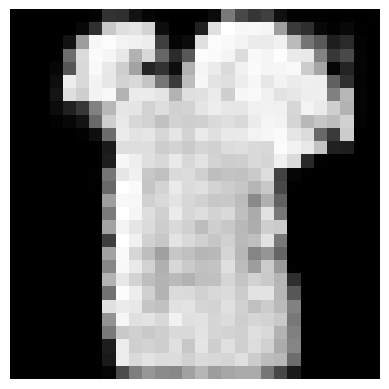

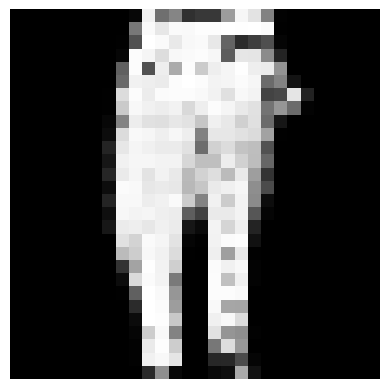

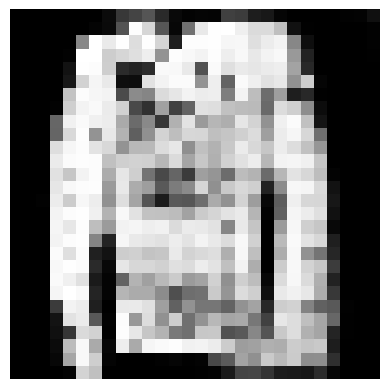

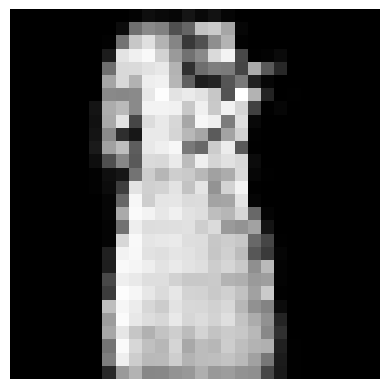

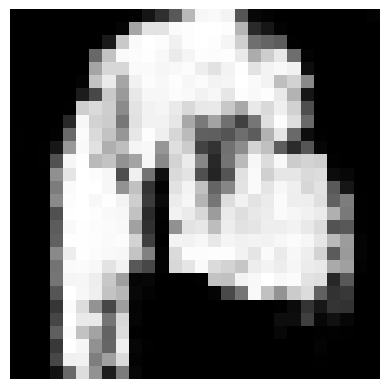

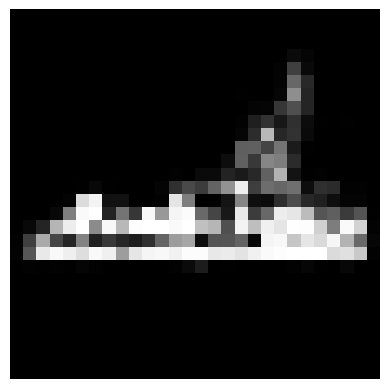

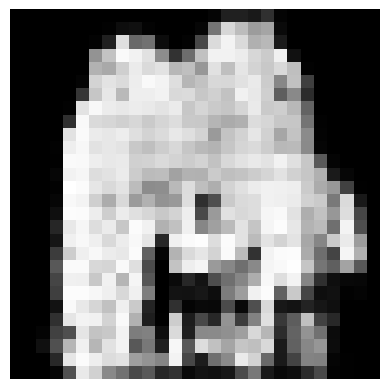

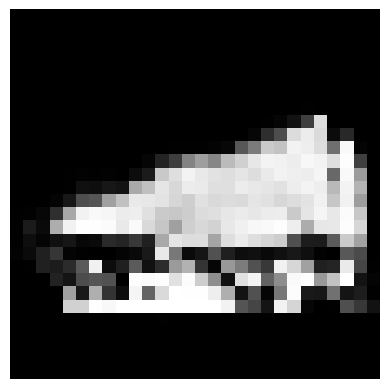

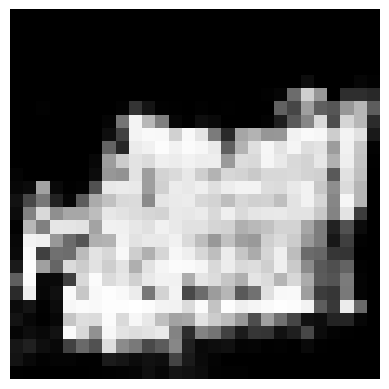

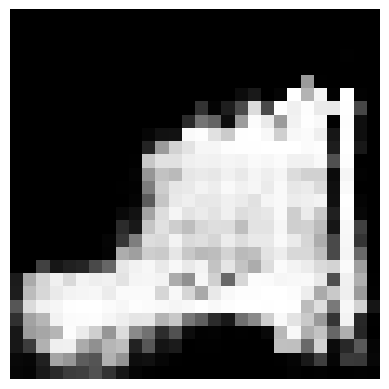

In [11]:
# Por último, mostramos las imágenes
for image in converted_images:
    plt.imshow(image[:,:,0], cmap='gray')
    plt.axis('off')
    plt.show()

En esta práctica se ha implementado una Conditional GAN (CGAN) a partir del notebook proporcionado, adaptándola al dataset FashionMNIST. A diferencia de MNIST, este conjunto de datos contiene imágenes de prendas de ropa, lo que aumenta la complejidad de la generación debido a la mayor variabilidad de formas y detalles.

Durante el entrenamiento, el generador y el discriminador compiten entre sí: el generador intenta crear imágenes sintéticas cada vez más realistas, mientras que el discriminador trata de diferenciar las imágenes reales de las generadas. La evolución de las pérdidas (d_loss y g_loss) muestra el comportamiento típico de una GAN, con oscilaciones derivadas de esta competición.

Finalmente, aunque el modelo ha conseguido aprender las características generales de cada clase, 20 épocas no son suficientes para obtener imágenes completamente nítidas.